# SINT-666 | Laboratorio 1  — Parte 2
**Universidad CENFOTEC · Trabajo individual**

**Investigación de la semana:** ¿Qué ocurriría si todas las capas de una red neuronal utilizaran únicamente funciones lineales?

Investigar: linealidad, composición de capas, ReLU, Sigmoid y Tanh.
Entregar: explicación propia, gráfico comparativo, ejemplo en Python y dos referencias técnicas.

**Entrega:** notebook ejecutado con código, gráficos, respuestas escritas y conclusiones.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

## 1. ¿Qué pasaría si todas las capas fueran lineales?

Sucedería que la red neuronal perdería todo el beneficio de tener varias capas. Una capa lineal solo multiplica y suma, y si apilo varias, el resultado sigue siendo una sola multiplicación y una suma, por lo que se puede decir que toda la red equivale a una sola capa, sin importar cuántas tenga.

Además, la red no podría captar relaciones complejas entre los datos: no lograría hacer curvas para definir los límites de decisión, y todo sería lineal.

**Linealidad:** es cuando una función se ve como una línea recta en el gráfico, por lo que un modelo lineal solo puede separar los datos con una recta y no con curvas.

**Composición de capas:** se refiere a cuando las capas se conectan una tras otra, por lo que lo que sale de una capa es lo que entra a la siguiente, como si fuera una cadena. Por ejemplo, si la capa 1 hace $h = 2x + 1$ y la capa 2 toma ese resultado y hace $y = 3h - 2$, al juntar las dos queda:

$$y = 3(2x + 1) - 2 = 6x + 1$$

Por lo que se puede decir que, aunque sean dos capas, al final el resultado sigue siendo una sola recta, y es como si solo hubiera una capa. En las redes reales se usan matrices en lugar de números sueltos, pero pasa exactamente lo mismo:

$$W_2(W_1x + b_1) + b_2 = (W_2W_1)x + (W_2b_1 + b_2) = Wx + b$$

O sea, por más capas lineales que se pongan, todas se pueden juntar en una sola, por lo que no se gana nada con agregar más.

**El ejemplo clásico es XOR:** la salida es 1 cuando las entradas son distintas y 0 cuando son iguales. Goodfellow et al. (2016, sección 6.1) muestran que ningún modelo lineal puede resolverlo: lo mejor que logra es responder 0.5 en todos los casos. En cambio, con una sola capa oculta con ReLU se resuelve perfectamente.

Por eso existen las funciones de activación: "doblan" el resultado entre una capa y otra, y eso le permite a la red aprender relaciones más complejas que una recta.

## 2. Ejemplo en Python: el problema XOR

Entrené dos redes neuronales reales en Keras con los datos de XOR. Las dos son iguales (2 → 8 → 1), lo único que cambia es la activación de la capa oculta: una usa ReLU y la otra es lineal.

Respuesta correcta: [1, 1, 0, 0]
Red con ReLU:       [1. 1. 0. 0.]
Red lineal:         [0.5 0.5 0.5 0.5]


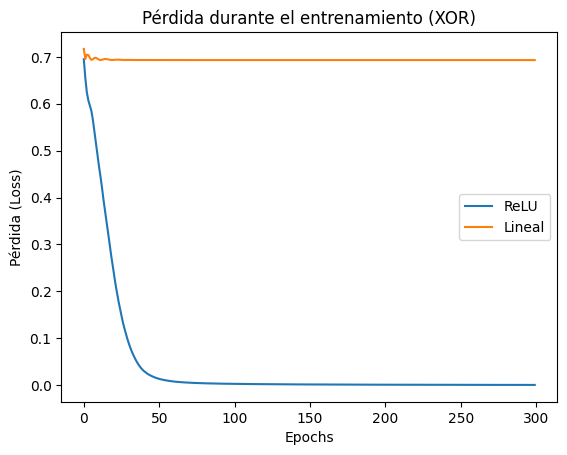

In [17]:
import tensorflow as tf
from tensorflow import keras

tf.keras.utils.set_random_seed(42)

# Datos XOR: la salida es 1 solo cuando las entradas son distintas
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([0, 1, 1, 0])

# Red con ReLU (no lineal): 2 -> 8 (ReLU) -> 1 (Sigmoid)
modelo_relu = keras.Sequential([keras.Input(shape=(2,)), keras.layers.Dense(8, activation="relu"), keras.layers.Dense(1, activation="sigmoid")])
modelo_relu.compile(optimizer=keras.optimizers.Adam(learning_rate=0.05), loss="binary_crossentropy", metrics=["accuracy"])
hist_relu = modelo_relu.fit(X, y, epochs=300, verbose=0)

# Misma red, pero con capa oculta lineal
modelo_lineal = keras.Sequential([keras.Input(shape=(2,)), keras.layers.Dense(8, activation="linear"), keras.layers.Dense(1, activation="sigmoid")])
modelo_lineal.compile(optimizer=keras.optimizers.Adam(learning_rate=0.05), loss="binary_crossentropy", metrics=["accuracy"])
hist_lineal = modelo_lineal.fit(X, y, epochs=300, verbose=0)

result = [1, 1, 0, 0]
input = np.array([[0, 1], [1, 0], [1, 1],[0, 0]])
print("Respuesta correcta:", result)
print("Red con ReLU:      ", np.round(modelo_relu.predict(input, verbose=0).ravel(), 2))
print("Red lineal:        ", np.round(modelo_lineal.predict(input, verbose=0).ravel(), 2))

plt.plot(hist_relu.history["loss"], label="ReLU")
plt.plot(hist_lineal.history["loss"], label="Lineal")
plt.title("Pérdida durante el entrenamiento (XOR)")
plt.xlabel("Epochs")
plt.ylabel("Pérdida (Loss)")
plt.legend()
plt.show()

**Interpretación:**

Entrené dos redes iguales con los datos de XOR, cambiando solo la activación de la capa oculta. La red con ReLU aprendió a responder bien los cuatro casos, mientras que la red lineal se quedó respondiendo 0.5 para todo, por lo que no logró aprender nada. En el gráfico también se ve: la pérdida de ReLU baja casi a 0, y la de la red lineal se queda plana.

La línea de la red lineal se queda fija en 0.69, que es justo la pérdida de un modelo que responde 0.5 para todo, como si adivinara al azar. Por lo que, aunque se entrene 300 épocas, nunca aprende.

Esto confirma que, aunque la red tenga varias capas, si todas son lineales no puede resolver problemas como XOR. Lo que resuelve el problema no es tener más capas, sino la **no linealidad**.

## 3. Gráfico comparativo

In [ ]:
x = np.linspace(-5, 5, 200)
sigmoid = 1 / (1 + np.exp(-x))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(x, x, "--", color="gray", label="Lineal")
ax[0].plot(x, sigmoid, label="Sigmoid")
ax[0].plot(x, np.tanh(x), label="Tanh")
ax[0].plot(x, np.maximum(0, x), label="ReLU")
ax[0].set_ylim(-1.5, 3)
ax[0].set_title("Funciones de activación")
ax[0].legend()

ax[1].plot(x, np.ones_like(x), "--", color="gray", label="Lineal")
ax[1].plot(x, sigmoid * (1 - sigmoid), label="Sigmoid")
ax[1].plot(x, 1 - np.tanh(x) ** 2, label="Tanh")
ax[1].plot(x, (x > 0).astype(float), label="ReLU")
ax[1].set_title("Derivadas (qué tan rápido aprende)")
ax[1].legend()

plt.show()

## 4. Comparación de funciones de activación

| Función | Rango | Lo bueno | Lo malo |
|---|---|---|---|
| Lineal | (−∞, ∞) | Simple | Varias capas lineales equivalen a una sola |
| Sigmoid | (0, 1) | Da una probabilidad, ideal para la salida | En valores grandes se "aplana" y la red casi deja de aprender |
| Tanh | (−1, 1) | Centrada en cero; suele funcionar mejor que Sigmoid en capas ocultas | También se aplana en los extremos |
| ReLU | [0, ∞) | Simple y rápida; es la recomendada por defecto para capas ocultas | Si una neurona siempre recibe negativos, se queda en 0 y deja de aprender |

En el gráfico de la derecha se ve por qué: las derivadas de Sigmoid y Tanh se acercan a 0 en los extremos, así que el aprendizaje se frena. ReLU mantiene la derivada en 1 para valores positivos.

## 8. Conclusiones y entrega

1. Varias capas lineales no le agregan capacidad a la red: matemáticamente se reducen a una sola.
2. Lo que de verdad le da poder a una red neuronal son las funciones de activación no lineales, como se vio con XOR.
3. Cada activación tiene su lugar: ReLU en las capas ocultas y Sigmoid en la salida cuando la respuesta es sí o no.

**Referencias:**
1. Goodfellow, I., Bengio, Y. y Courville, A. (2016). *Deep Learning*, capítulo 6: Deep Feedforward Networks (secciones 6.1 y 6.3). MIT Press. https://www.deeplearningbook.org/contents/mlp.html
2. Keras. *Layer activation functions*. https://keras.io/api/layers/activations/